# Trabajo Práctico 3 · Algoritmos de clasificación y evaluación de modelos
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**
**Integrantes:** Gino Ficetto y Bautista Ferrer

**Pregunta de clasificación.** A partir de los caracteres que se conocen temprano (las DEP de peso al nacer, peso al destete, aptitud materna y circunferencia escrotal, y el año de nacimiento), ¿el toro va a estar en el **10 % superior de su raza en peso a los 18 meses** (RANK ≤ 10)?

| | |
|---|---|
| **Datos** | Sumarios de padres 2026 de la Asociación Braford Argentina y de la Asociación Argentina de Brangus: 2329 toros (1106 Braford y 1223 Brangus), la base del TP1. |
| **Objetivo (target)** | `top10` = 1 si `Peso18Meses_RANK` ≤ 10, 0 si no. Clasificación **binaria**. |
| **Algoritmos** | Regresión logística (línea base), k vecinos más cercanos y Random Forest. Random Forest es además el **método de ensamble** (bagging) que se compara con los clasificadores individuales. |
| **Actividad complementaria** | Clustering con tres algoritmos, uno de cada familia que nombra la consigna: **K-Means** (centroides), **aglomerativo con enlace de Ward** (jerárquico) y **DBSCAN** (densidad), sobre las mismas variables y comparados con la clase real. |
| **Raza** | Braford es el análisis principal; la sección 7 replica todo en Brangus. |
| **Reproducibilidad** | Semilla 2026 en la partición, la validación cruzada, los modelos y el clustering. Las figuras se guardan en `figuras/` y los números en `resultados_tp3.json`. |

Es la misma pregunta del TP2 vista como clasificación: el TP2 estimó **cuántos** kg; este trabajo decide **si** el toro estará entre los mejores.

## 0 · Preparación del entorno

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, cohen_kappa_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)
from sklearn.inspection import permutation_importance

SEMILLA = 2026
RAZA = "Braford"                 # raza principal; la sección 7 replica todo en Brangus
PREDICTORAS = ["PesoNacer_DEP", "PesoDestete_DEP", "AptitudMaterna_DEP", "CircEscrotal_DEP", "Anio_Nacimiento"]
NOMBRES = {"PesoNacer_DEP": "DEP nacer", "PesoDestete_DEP": "DEP destete", "AptitudMaterna_DEP": "DEP aptitud materna",
           "CircEscrotal_DEP": "DEP circ. escrotal", "Anio_Nacimiento": "Año de nacimiento"}
CLASES = ["no top", "top 10 %"]
AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
COLOR_MODELO = {"Regresión logística": AZUL, "k vecinos": AMBAR, "Random Forest": VERDE}
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

toros = pd.read_csv("datos/toros_braford_brangus.csv")
toros["top10"] = (toros["Peso18Meses_RANK"] <= 10).astype(int)
print(f"Base completa: {len(toros)} toros ({(toros.Raza == 'Braford').sum()} Braford, {(toros.Raza == 'Brangus').sum()} Brangus)")

Base completa: 2329 toros (1106 Braford, 1223 Brangus)


## A · Marco experimental

### A.1 · El problema y su relevancia
El RANK es la banda percentil de la DEP de un toro contra toda la población evaluada de su raza (Sumario Braford 2026, págs. 12 a 14): RANK ≤ 10 es estar en el 10 % superior. Para un productor, saber si un toro joven va a estar en ese grupo antes de que su DEP de 18 meses sea confiable sirve para decidir qué pajuelas comprar o qué toro probar. Es una clasificación **binaria**: top 10 % o no.

### A.2 · Distribución de clases

         toros  top 10 %  proporción
Raza                                
Braford   1106       417       0.377
Brangus   1223       466       0.381


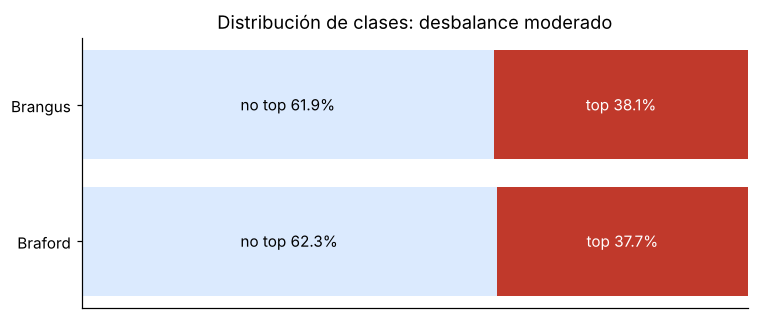

In [2]:
datos = toros[toros["Raza"] == RAZA].reset_index(drop=True)
conteo = toros.groupby("Raza")["top10"].agg(["size", "sum", "mean"]).rename(columns={"size": "toros", "sum": "top 10 %", "mean": "proporción"})
print(conteo.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 3))
for i, raza in enumerate(["Braford", "Brangus"]):
    p = toros.loc[toros.Raza == raza, "top10"].mean()
    ax.barh(i, 1 - p, color="#dbeafe"); ax.barh(i, p, left=1 - p, color=ROJO)
    ax.text((1 - p) / 2, i, f"no top {1 - p:.1%}", ha="center", va="center"); ax.text(1 - p / 2, i, f"top {p:.1%}", ha="center", va="center", color="white")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Braford", "Brangus"]); ax.set_xlim(0, 1); ax.set_xticks([])
ax.set_title("Distribución de clases: desbalance moderado")
plt.tight_layout(); fig.savefig(FIG / "tp3_clases.png", bbox_inches="tight"); plt.show()

**Qué se ve.** El 37,7 % de los toros Braford y el 38,1 % de los Brangus están en el top 10 %. No es una contradicción: el 10 % se mide contra **toda la población evaluada**, y los toros del sumario ya son padres elegidos. El **desbalance es moderado** (cerca de 62/38): una referencia que diga siempre «no top» acierta el 62 %, así que la exactitud sola engaña; por eso se miran precisión, exhaustividad, F1, Kappa y AUC, se estratifica la partición y se prueba pesar las clases (sección C.4).

### A.3 · Variables predictoras
- **Incluidas:** las cuatro DEP tempranas y el año de nacimiento (tendencia genética), las mismas del TP2.
- **Excluidas:** la DEP y el RANK de 18 meses (de ellos sale la etiqueta: incluirlos sería **fuga de información**); Leche y Crecimiento (es exactamente aptitud materna + ½ destete, como se verificó en el TP2); precisiones, crías y rodeos (miden la confiabilidad o el uso del toro, no su genética); identificadores.

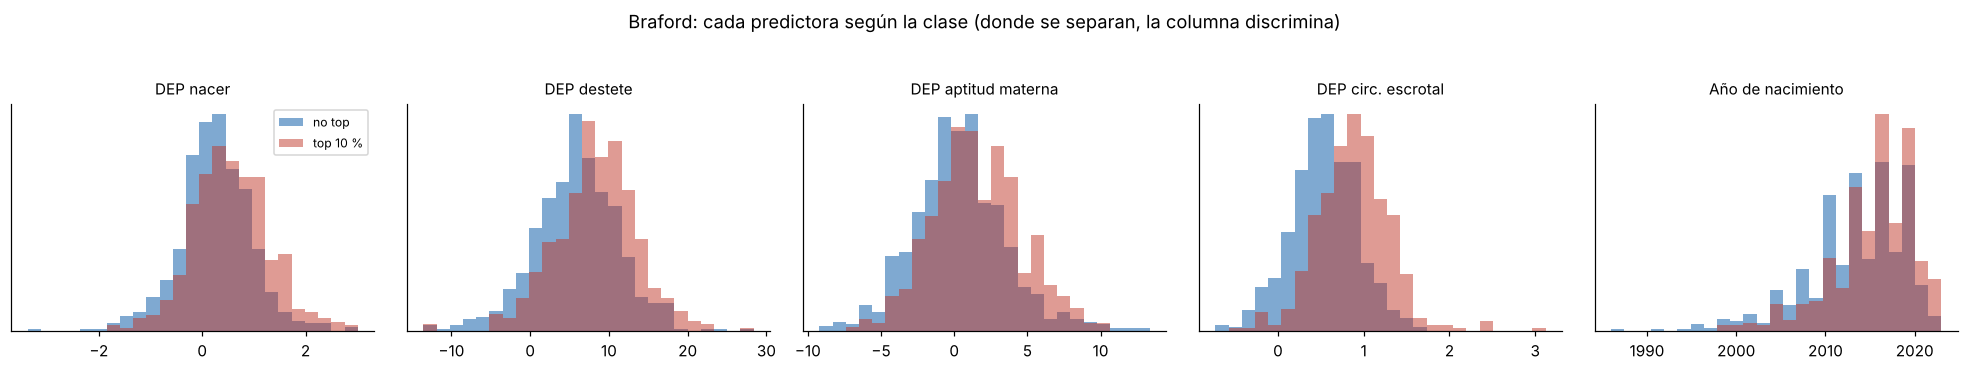

Media de cada predictora por clase:
          DEP nacer  DEP destete  DEP aptitud materna  DEP circ. escrotal  Año de nacimiento
top10                                                                                       
no top         0.25         5.87                 0.37                0.54            2013.46
top 10 %       0.56         8.39                 1.57                0.88            2015.52


In [3]:
fig, ejes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, col in zip(ejes, PREDICTORAS):
    v = datos[col].dropna(); bins = np.histogram_bin_edges(v, bins=25)
    for c, color in [(0, AZUL), (1, ROJO)]:
        ax.hist(datos.loc[datos.top10 == c, col].dropna(), bins=bins, density=True, alpha=0.5, color=color, label=CLASES[c])
    ax.set_title(NOMBRES[col], fontsize=10); ax.set_yticks([])
ejes[0].legend(fontsize=8)
fig.suptitle(f"{RAZA}: cada predictora según la clase (donde se separan, la columna discrimina)", y=1.04)
plt.tight_layout(); fig.savefig(FIG / f"tp3_eda_{RAZA}.png", bbox_inches="tight"); plt.show()
print("Media de cada predictora por clase:")
print(datos.groupby("top10")[PREDICTORAS].mean().rename(index=dict(enumerate(CLASES)), columns=NOMBRES).round(2).to_string())

**Qué se ve.** Ninguna variable separa sola a las dos clases: las distribuciones se superponen. La clase top 10 % tiene en promedio más destete (8,4 contra 5,9 kg), más aptitud materna (1,6 contra 0,4 kg), más circunferencia escrotal (0,88 contra 0,54 cm) y es un poco más nueva (2015 contra 2013).

### A.4 · Partición
- **Hold-out estratificado 80/20** (`stratify=y`, semilla 2026): la prueba conserva la misma proporción de toros top que el total.
- **Validación cruzada estratificada de 5 pliegues** (`StratifiedKFold`) sobre el entrenamiento, para elegir hiperparámetros y estimar el rendimiento con su dispersión.
- Imputación (un solo faltante: el año de un toro) y escalado adentro de un `Pipeline`.

In [4]:
X = datos[PREDICTORAS]
y = datos["top10"]
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_ent)} toros ({y_ent.mean():.1%} top) · prueba: {len(X_pru)} toros ({y_pru.mean():.1%} top, {y_pru.sum()} toros top) · semilla {SEMILLA}")

Entrenamiento: 884 toros (37.7% top) · prueba: 222 toros (37.8% top, 84 toros top) · semilla 2026


### A.5 · Métricas y línea base
Obligatorias: **exactitud, precisión, exhaustividad (recall) y F1** (por clase y ponderado, con `classification_report`) y **matriz de confusión** de cada modelo. Complementarias: **AUC** (curva ROC), **precisión promedio** (curva precisión-exhaustividad) y **Kappa de Cohen**. Todas en entrenamiento y en prueba.

La **línea base** de la consigna es la regresión logística (sección B.1). Antes se registra una referencia trivial que predice siempre la clase más frecuente.

In [5]:
def metricas(y_real, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {"Exactitud": accuracy_score(y_real, pred), "Precisión": precision_score(y_real, pred, zero_division=0),
            "Exhaustividad": recall_score(y_real, pred), "F1": f1_score(y_real, pred, zero_division=0),
            "F1 ponderado": f1_score(y_real, pred, average="weighted"), "Kappa": cohen_kappa_score(y_real, pred),
            "AUC": roc_auc_score(y_real, prob) if len(np.unique(prob)) > 1 else 0.5, "AP": average_precision_score(y_real, prob)}

resultados = {}
def registrar(nombre, modelo, ajustar=True, umbral=0.5):
    if ajustar:
        t0 = time.perf_counter(); modelo.fit(X_ent, y_ent); t = time.perf_counter() - t0
    else:
        t = np.nan
    cv = cross_validate(modelo, X_ent, y_ent, cv=pliegues, scoring=("roc_auc", "f1"))
    pe, pp = modelo.predict_proba(X_ent)[:, 1], modelo.predict_proba(X_pru)[:, 1]
    resultados[nombre] = {"modelo": modelo, "entrenamiento": metricas(y_ent, pe, umbral), "prueba": metricas(y_pru, pp, umbral),
                          "AUC CV": (cv["test_roc_auc"].mean(), cv["test_roc_auc"].std()), "F1 CV": (cv["test_f1"].mean(), cv["test_f1"].std()),
                          "ajuste (s)": t, "prob": pp, "umbral": umbral}
    e, p = resultados[nombre]["entrenamiento"], resultados[nombre]["prueba"]
    print(f"{nombre}: AUC entrenamiento {e['AUC']:.3f} · prueba {p['AUC']:.3f} | F1 entrenamiento {e['F1']:.3f} · prueba {p['F1']:.3f} | "
          f"AUC CV {resultados[nombre]['AUC CV'][0]:.3f} ± {resultados[nombre]['AUC CV'][1]:.3f}")
    return modelo

def flujo(modelo, escalar=True):
    pasos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar: pasos.append(("escalar", StandardScaler()))
    return Pipeline(pasos + [("modelo", modelo)])

registrar("Referencia: la clase más frecuente", flujo(DummyClassifier(strategy="most_frequent"), escalar=False));
r = resultados["Referencia: la clase más frecuente"]["prueba"]
print(f"La referencia acierta el {r['Exactitud']:.1%} sin encontrar ningún toro top (exhaustividad {r['Exhaustividad']:.0%}, Kappa {r['Kappa']:.2f}).")

Referencia: la clase más frecuente: AUC entrenamiento 0.500 · prueba 0.500 | F1 entrenamiento 0.000 · prueba 0.000 | AUC CV 0.500 ± 0.000
La referencia acierta el 62.2% sin encontrar ningún toro top (exhaustividad 0%, Kappa 0.00).


## B · Implementación y entrenamiento

### B.1 · Regresión logística (línea base)
**Hiperparámetros:** los de la biblioteca (`C=1`, regularización ℓ2 suave) con `max_iter=1000`. Las predictoras se escalan para que el optimizador converja y los coeficientes se puedan comparar.

In [6]:
logistica = registrar("Regresión logística", flujo(LogisticRegression(max_iter=1000)))
lr = logistica["modelo"]
odds = pd.DataFrame({"coef_ (log-chances por desvío)": lr.coef_[0], "razón de chances e^b": np.exp(lr.coef_[0])},
                    index=[NOMBRES[c] for c in PREDICTORAS]).sort_values("coef_ (log-chances por desvío)", ascending=False)
print(f"\nintercept_ = {lr.intercept_[0]:.3f} → probabilidad del toro promedio = {1 / (1 + np.exp(-lr.intercept_[0])):.2f}")
odds.round(3)

Regresión logística: AUC entrenamiento 0.826 · prueba 0.774 | F1 entrenamiento 0.687 · prueba 0.596 | AUC CV 0.820 ± 0.021

intercept_ = -0.708 → probabilidad del toro promedio = 0.33


,coef_ (log-chances por desvío),razón de chances e^b
DEP aptitud materna,1.060,2.886
DEP destete,1.022,2.778
DEP circ. escrotal,0.735,2.085
DEP nacer,0.252,1.287
Año de nacimiento,0.203,1.225


**Lectura y ajuste.** Cada coeficiente, con las columnas escaladas, multiplica las chances de ser top 10 % por la razón de chances de la derecha cuando la variable sube un desvío estándar. Aptitud materna (×2,9) y destete (×2,8) pesan más; después la circunferencia escrotal (×2,1). AUC 0,826 en entrenamiento y 0,774 en prueba: **brecha chica**, sin sobreajuste relevante; la validación cruzada (0,820 ± 0,021) confirma el nivel.

### B.2 · k vecinos más cercanos
**Por qué:** clasifica a cada toro por el voto de los k toros con DEP más parecidas; no supone ninguna forma para la frontera.

**Hiperparámetros:** `n_neighbors` con `GridSearchCV` (AUC, 5 pliegues estratificados) entre 3 y 151; `weights="uniform"` (con `"distance"` el entrenamiento queda acertado por construcción y no se puede diagnosticar el sobreajuste). Escalado obligatorio.

Mejor combinación: {'modelo__n_neighbors': 101, 'modelo__weights': 'uniform'} · AUC CV = 0.813


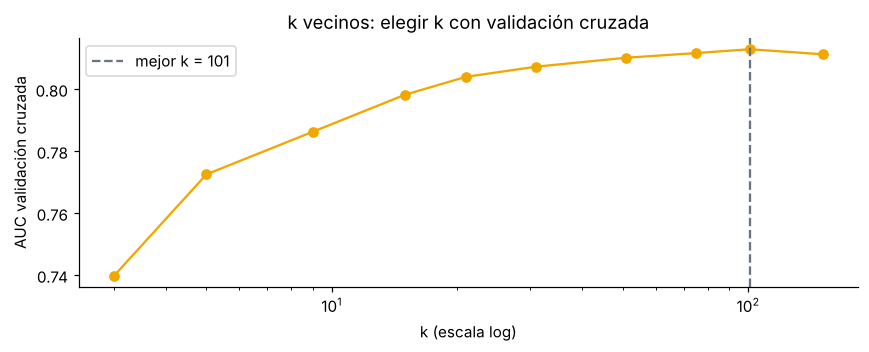

k vecinos (k = 5, por defecto): AUC entrenamiento 0.903 · prueba 0.728 | F1 entrenamiento 0.741 · prueba 0.604 | AUC CV 0.773 ± 0.019
k vecinos: AUC entrenamiento 0.826 · prueba 0.786 | F1 entrenamiento 0.601 · prueba 0.538 | AUC CV 0.813 ± 0.018


In [7]:
grilla_knn = {"modelo__n_neighbors": [3, 5, 9, 15, 21, 31, 51, 75, 101, 151], "modelo__weights": ["uniform"]}
busq_knn = GridSearchCV(flujo(KNeighborsClassifier()), grilla_knn, cv=pliegues, scoring="roc_auc").fit(X_ent, y_ent)
print("Mejor combinación:", busq_knn.best_params_, f"· AUC CV = {busq_knn.best_score_:.3f}")
tk = pd.DataFrame(busq_knn.cv_results_)
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(tk["param_modelo__n_neighbors"], tk["mean_test_score"], marker="o", color=AMBAR)
ax.axvline(busq_knn.best_params_["modelo__n_neighbors"], color=GRIS, ls="--", label=f"mejor k = {busq_knn.best_params_['modelo__n_neighbors']}")
ax.set_xscale("log"); ax.set_xlabel("k (escala log)"); ax.set_ylabel("AUC validación cruzada"); ax.legend()
ax.set_title("k vecinos: elegir k con validación cruzada")
plt.tight_layout(); fig.savefig(FIG / f"tp3_knn_k_{RAZA}.png", bbox_inches="tight"); plt.show()
registrar("k vecinos (k = 5, por defecto)", flujo(KNeighborsClassifier()))
knn = registrar("k vecinos", busq_knn.best_estimator_, ajustar=False)

**Lectura y ajuste.** Con k = 5 **sobreajusta**: AUC 0,903 en entrenamiento y 0,728 en prueba. La validación cruzada elige **k = 101**: con tantos vecinos el voto se suaviza y la brecha casi desaparece (0,826 contra 0,786). Un k tan grande dice que la frontera entre clases es suave, casi lineal.

### B.3 · Random Forest (ensamble por bagging)
**Por qué:** 300 árboles de decisión, cada uno entrenado con una muestra con reposición de los toros, que votan promediando sus probabilidades. Captura interacciones y no linealidades y reduce la varianza de un árbol solo.

**Hiperparámetros:** `n_estimators=300` fijo. Con `GridSearchCV` (AUC): `max_depth` (sin límite, 4, 6, 8, 12), `min_samples_leaf` (1, 5, 10, 20), `max_features` (raíz cuadrada o todas): 40 combinaciones por 5 pliegues. No necesita escalar.

In [8]:
registrar("Random Forest (por defecto)", flujo(RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1), escalar=False))
grilla_rf = {"modelo__max_depth": [None, 4, 6, 8, 12], "modelo__min_samples_leaf": [1, 5, 10, 20], "modelo__max_features": ["sqrt", 1.0]}
busq_rf = GridSearchCV(flujo(RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1), escalar=False),
                       grilla_rf, cv=pliegues, scoring="roc_auc", n_jobs=-1).fit(X_ent, y_ent)
print("Mejor combinación:", busq_rf.best_params_, f"· AUC CV = {busq_rf.best_score_:.3f}")
rf = registrar("Random Forest", busq_rf.best_estimator_, ajustar=False)

Random Forest (por defecto): AUC entrenamiento 1.000 · prueba 0.731 | F1 entrenamiento 1.000 · prueba 0.571 | AUC CV 0.794 ± 0.022


Mejor combinación: {'modelo__max_depth': 6, 'modelo__max_features': 1.0, 'modelo__min_samples_leaf': 10} · AUC CV = 0.804


Random Forest: AUC entrenamiento 0.908 · prueba 0.759 | F1 entrenamiento 0.763 · prueba 0.596 | AUC CV 0.804 ± 0.019


**Lectura y ajuste.** Con los valores por defecto el bosque **memoriza**: AUC y F1 de 1,000 en entrenamiento, 0,731 de AUC en prueba. Con profundidad 6 y al menos 10 toros por hoja, la validación cruzada sube a 0,804, pero queda una brecha de 0,15 de AUC entre entrenamiento (0,908) y prueba (0,759): **es el modelo con más varianza de los tres**.

## C · Evaluación y comparación

### C.1 · Tabla comparativa: entrenamiento y prueba

In [9]:
FINALES = ["Regresión logística", "k vecinos", "Random Forest"]
filas = []
for nombre, r in resultados.items():
    for parte in ["entrenamiento", "prueba"]:
        filas.append({"Modelo": nombre, "Conjunto": parte, **r[parte]})
tabla = pd.DataFrame(filas).set_index(["Modelo", "Conjunto"])
display(tabla.style.format("{:.3f}"))
pd.DataFrame({n: {"AUC CV (media ± desvío)": f"{r['AUC CV'][0]:.3f} ± {r['AUC CV'][1]:.3f}",
                  "F1 CV (media ± desvío)": f"{r['F1 CV'][0]:.3f} ± {r['F1 CV'][1]:.3f}"} for n, r in resultados.items()}).T

,AUC CV (media ± desvío),F1 CV (media ± desvío)
Referencia: la clase más frecuente,0.500 ± 0.000,0.000 ± 0.000
Regresión logística,0.820 ± 0.021,0.672 ± 0.035
"k vecinos (k = 5, por defecto)",0.773 ± 0.019,0.613 ± 0.042
k vecinos,0.813 ± 0.018,0.551 ± 0.031
Random Forest (por defecto),0.794 ± 0.022,0.647 ± 0.025
Random Forest,0.804 ± 0.019,0.644 ± 0.027


### C.2 · Precisión, exhaustividad y F1 por clase

In [10]:
for n in FINALES:
    print(f"===== {n} (prueba, umbral 0,5)")
    print(classification_report(y_pru, (resultados[n]["prob"] >= 0.5).astype(int), target_names=CLASES, digits=3))

===== Regresión logística (prueba, umbral 0,5)
              precision    recall  f1-score   support

      no top      0.748     0.841     0.792       138
    top 10 %      0.672     0.536     0.596        84

    accuracy                          0.725       222
   macro avg      0.710     0.688     0.694       222
weighted avg      0.719     0.725     0.718       222

===== k vecinos (prueba, umbral 0,5)
              precision    recall  f1-score   support

      no top      0.722     0.920     0.809       138
    top 10 %      0.761     0.417     0.538        84

    accuracy                          0.730       222
   macro avg      0.741     0.668     0.674       222
weighted avg      0.736     0.730     0.707       222

===== Random Forest (prueba, umbral 0,5)
              precision    recall  f1-score   support

      no top      0.745     0.891     0.812       138
    top 10 %      0.737     0.500     0.596        84

    accuracy                          0.743       222
   

### C.3 · Matrices de confusión

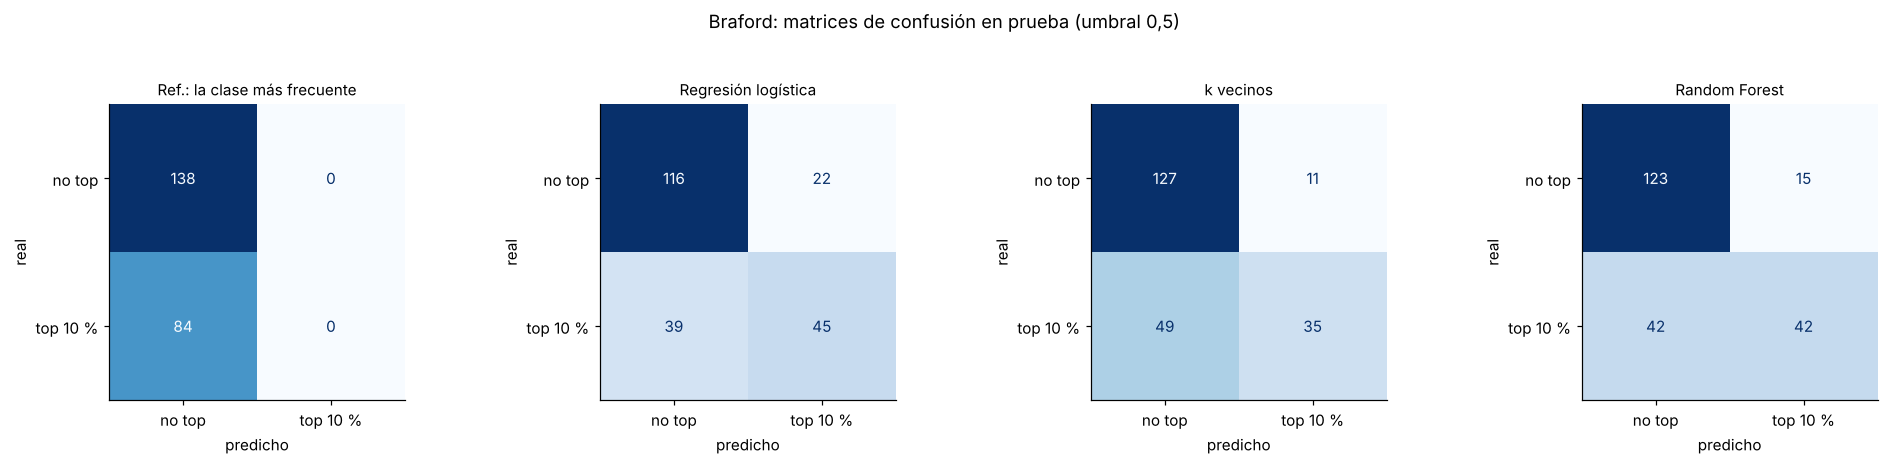

In [11]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for ax, n in zip(ejes, ["Referencia: la clase más frecuente"] + FINALES):
    cm = confusion_matrix(y_pru, (resultados[n]["prob"] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(n.replace("Referencia: ", "Ref.: "), fontsize=10); ax.set_xlabel("predicho"); ax.set_ylabel("real")
fig.suptitle(f"{RAZA}: matrices de confusión en prueba (umbral 0,5)", y=1.04)
plt.tight_layout(); fig.savefig(FIG / f"tp3_matrices_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** La referencia marca a todos como «no top» y no encuentra a ninguno de los 84 toros top de la prueba. Los tres modelos aciertan bien la clase mayoritaria y encuentran entre el 42 % (k vecinos) y el 54 % (logística) de los toros top con el umbral de 0,5. Su error típico es el **falso negativo**: dejar pasar un toro top. Eso es lo esperable con un 38 % de positivos y el umbral en 0,5.

### C.4 · Curvas ROC y precisión-exhaustividad

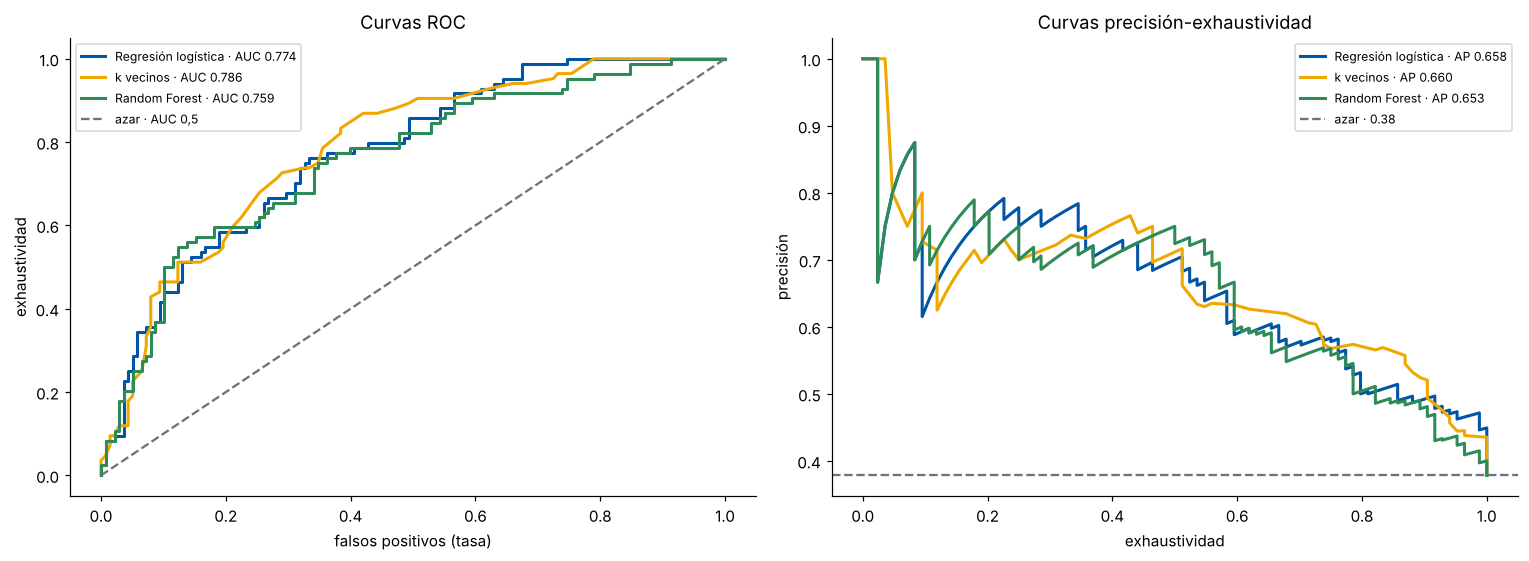

In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.2))
for n in FINALES:
    fpr, tpr, _ = roc_curve(y_pru, resultados[n]["prob"]); a.plot(fpr, tpr, lw=2, color=COLOR_MODELO[n], label=f"{n} · AUC {resultados[n]['prueba']['AUC']:.3f}")
    pr, rc, _ = precision_recall_curve(y_pru, resultados[n]["prob"]); b.plot(rc, pr, lw=2, color=COLOR_MODELO[n], label=f"{n} · AP {resultados[n]['prueba']['AP']:.3f}")
a.plot([0, 1], [0, 1], ls="--", color=GRIS, label="azar · AUC 0,5"); a.set_xlabel("falsos positivos (tasa)"); a.set_ylabel("exhaustividad"); a.set_title("Curvas ROC"); a.legend(fontsize=8)
b.axhline(y_pru.mean(), ls="--", color=GRIS, label=f"azar · {y_pru.mean():.2f}"); b.set_xlabel("exhaustividad"); b.set_ylabel("precisión"); b.set_title("Curvas precisión-exhaustividad"); b.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG / f"tp3_roc_pr_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** Las tres curvas ROC casi se superponen, muy por encima del azar: los tres modelos **ordenan** a los toros por chance de ser top de forma parecida (AUC entre 0,76 y 0,79 en prueba). La curva precisión-exhaustividad dice lo mismo: no hay un modelo que domine en todo el rango.

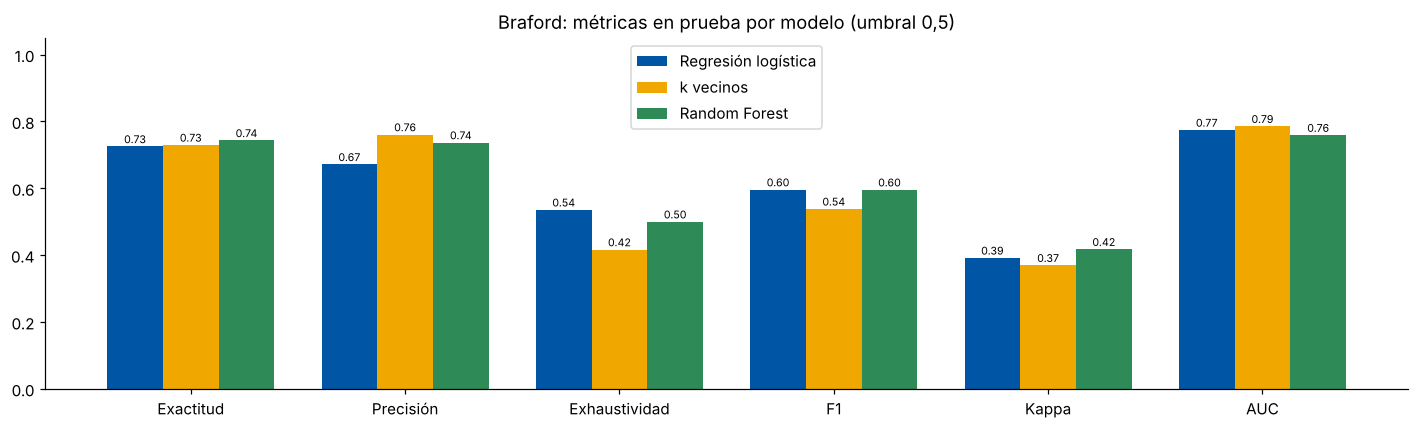

In [13]:
mets = ["Exactitud", "Precisión", "Exhaustividad", "F1", "Kappa", "AUC"]
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(len(mets)); w = 0.26
for i, n in enumerate(FINALES):
    v = [resultados[n]["prueba"][m] for m in mets]
    ax.bar(x + (i - 1) * w, v, w, color=COLOR_MODELO[n], label=n)
    for xi, vi in zip(x + (i - 1) * w, v): ax.text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(mets); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title(f"{RAZA}: métricas en prueba por modelo (umbral 0,5)")
plt.tight_layout(); fig.savefig(FIG / f"tp3_metricas_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** Con el umbral de 0,5 cada modelo gana en una métrica distinta: Random Forest en exactitud y Kappa, k vecinos en precisión, la logística en exhaustividad y F1. Por eso la elección se hace con una métrica que no depende del umbral.

### C.5 · El mejor clasificador
Criterio principal: **AUC en validación cruzada**, que no depende del umbral y usa los 884 toros de entrenamiento en cinco particiones estratificadas.

In [14]:
orden = sorted(FINALES, key=lambda n: -resultados[n]["AUC CV"][0])
MEJOR = orden[0]
print("Orden por AUC de validación cruzada (criterio principal):")
for n in orden:
    r = resultados[n]
    print(f"  {n:20s} AUC CV {r['AUC CV'][0]:.3f} ± {r['AUC CV'][1]:.3f} · AUC prueba {r['prueba']['AUC']:.3f} · F1 {r['prueba']['F1']:.3f} · "
          f"precisión {r['prueba']['Precisión']:.3f} · exhaustividad {r['prueba']['Exhaustividad']:.3f}")
print(f"\nMejor clasificador: {MEJOR}")
for m in ["Precisión", "Exhaustividad", "F1", "Exactitud"]:
    print(f"  Si se prioriza {m} en prueba, gana: {max(FINALES, key=lambda n: resultados[n]['prueba'][m])}")

Orden por AUC de validación cruzada (criterio principal):
  Regresión logística  AUC CV 0.820 ± 0.021 · AUC prueba 0.774 · F1 0.596 · precisión 0.672 · exhaustividad 0.536
  k vecinos            AUC CV 0.813 ± 0.018 · AUC prueba 0.786 · F1 0.538 · precisión 0.761 · exhaustividad 0.417
  Random Forest        AUC CV 0.804 ± 0.019 · AUC prueba 0.759 · F1 0.596 · precisión 0.737 · exhaustividad 0.500

Mejor clasificador: Regresión logística
  Si se prioriza Precisión en prueba, gana: k vecinos
  Si se prioriza Exhaustividad en prueba, gana: Regresión logística
  Si se prioriza F1 en prueba, gana: Regresión logística
  Si se prioriza Exactitud en prueba, gana: Random Forest


**La elección:** **regresión logística**. Tiene el AUC de validación cruzada más alto (0,820 ± 0,021, contra 0,813 de k vecinos y 0,804 de Random Forest), el mejor F1 y la mayor exhaustividad en prueba, la menor brecha entre entrenamiento y prueba, y es el más simple e interpretable. Las diferencias de AUC entre los tres son menores que el desvío entre pliegues: **empate técnico**, que se resuelve a favor del modelo más simple. Si se priorizara la **precisión** (no recomendar un toro que no es top), ganaría k vecinos (0,761 contra 0,672); si se priorizara la **exhaustividad** (no dejar pasar un toro top), gana la logística (0,536).

### C.6 · Tratamiento del desbalance
Además de estratificar, se prueba `class_weight="balanced"`, que hace pesar más a cada toro top durante el entrenamiento. Se aplica a la logística y al bosque (k vecinos no admite pesos de clase).

In [15]:
print("Estrategia frente al desbalance: pesar las clases (class_weight='balanced') y comparar.")
registrar("Regresión logística, clases pesadas", flujo(LogisticRegression(max_iter=1000, class_weight="balanced")))
p_rf = {k.replace("modelo__", ""): v for k, v in busq_rf.best_params_.items()}
registrar("Random Forest, clases pesadas", flujo(RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1, class_weight="balanced", **p_rf), escalar=False))
comp = pd.DataFrame({n: resultados[n]["prueba"] for n in ["Regresión logística", "Regresión logística, clases pesadas", "Random Forest", "Random Forest, clases pesadas"]}).T
comp[["Exactitud", "Precisión", "Exhaustividad", "F1", "Kappa", "AUC"]].round(3)

Estrategia frente al desbalance: pesar las clases (class_weight='balanced') y comparar.
Regresión logística, clases pesadas: AUC entrenamiento 0.826 · prueba 0.773 | F1 entrenamiento 0.709 · prueba 0.613 | AUC CV 0.820 ± 0.020


Random Forest, clases pesadas: AUC entrenamiento 0.910 · prueba 0.754 | F1 entrenamiento 0.784 · prueba 0.614 | AUC CV 0.801 ± 0.022


,Exactitud,Precisión,Exhaustividad,F1,Kappa,AUC
Regresión logística,0.725,0.672,0.536,0.596,0.392,0.774
"Regresión logística, clases pesadas",0.698,0.596,0.631,0.613,0.366,0.773
Random Forest,0.743,0.737,0.500,0.596,0.418,0.759
"Random Forest, clases pesadas",0.712,0.622,0.607,0.614,0.384,0.754


**Qué se ve.** Pesar las clases **no cambia el AUC** (la capacidad de ordenar es la misma) pero corre la decisión: la exhaustividad de la logística sube de 0,54 a 0,63 y el F1 de 0,60 a 0,61, a cambio de menos precisión (0,67 a 0,60) y menos exactitud. Con un desbalance moderado como este, el efecto es el mismo que bajar el umbral (sección siguiente); no hizo falta sobremuestreo (SMOTE).

### C.7 · Análisis del umbral de decisión (extensión)

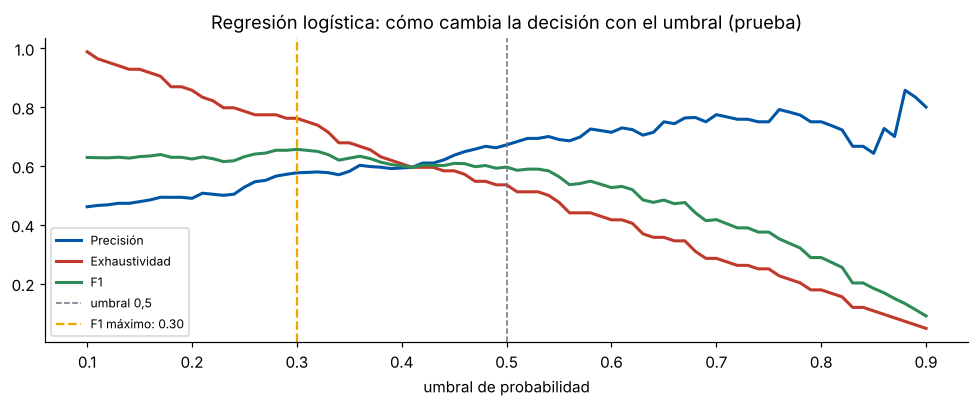

umbral 0.50: precisión 0.67 · exhaustividad 0.54 · F1 0.60
umbral 0.40: precisión 0.59 · exhaustividad 0.61 · F1 0.60
umbral 0.30: precisión 0.58 · exhaustividad 0.76 · F1 0.66


In [16]:
prob = resultados[MEJOR]["prob"]
umbrales = np.linspace(0.1, 0.9, 81)
curva = pd.DataFrame([{"umbral": u, **{k: v for k, v in metricas(y_pru, prob, u).items() if k in ["Precisión", "Exhaustividad", "F1"]}} for u in umbrales])
u_f1 = curva.loc[curva["F1"].idxmax(), "umbral"]
fig, ax = plt.subplots(figsize=(9, 3.8))
for m, c in [("Precisión", AZUL), ("Exhaustividad", ROJO), ("F1", VERDE)]:
    ax.plot(curva["umbral"], curva[m], color=c, lw=2, label=m)
ax.axvline(0.5, color=GRIS, ls="--", lw=1, label="umbral 0,5"); ax.axvline(u_f1, color=AMBAR, ls="--", lw=1.5, label=f"F1 máximo: {u_f1:.2f}")
ax.set_xlabel("umbral de probabilidad"); ax.legend(fontsize=8); ax.set_title(f"{MEJOR}: cómo cambia la decisión con el umbral (prueba)")
plt.tight_layout(); fig.savefig(FIG / f"tp3_umbral_{RAZA}.png", bbox_inches="tight"); plt.show()
for u in sorted({0.5, round(float(u_f1), 2), 0.4}, reverse=True):
    m = metricas(y_pru, prob, u)
    print(f"umbral {u:.2f}: precisión {m['Precisión']:.2f} · exhaustividad {m['Exhaustividad']:.2f} · F1 {m['F1']:.2f}")

**Qué se ve.** Con el umbral de 0,5 la logística encuentra el 54 % de los toros top; con **0,30** encuentra el **76 %**, con precisión 0,58 y el **F1 máximo (0,66)**. Para un productor que usa el modelo como **primer filtro** (para después mirar con detalle a los toros marcados), conviene el umbral bajo: dejar pasar un toro top cuesta más que revisar uno de más.

### C.8 · Curvas de aprendizaje (extensión)

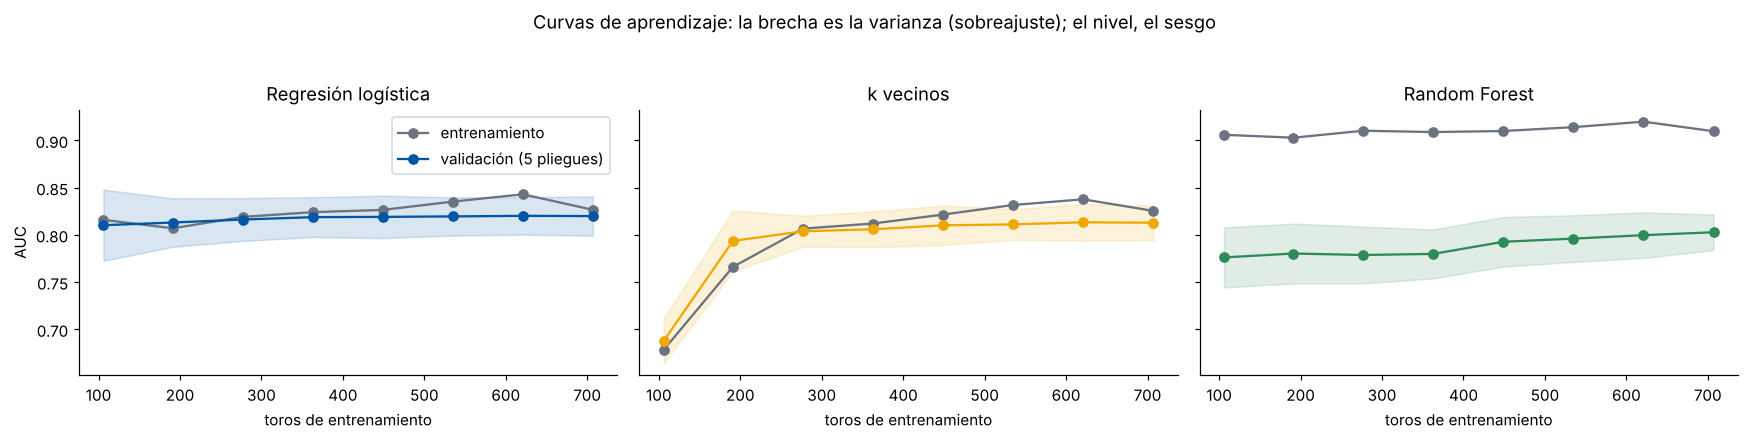

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, n in zip(ejes, FINALES):
    tam, te, tv = learning_curve(resultados[n]["modelo"], X_ent, y_ent, cv=pliegues, train_sizes=np.linspace(0.15, 1.0, 8), scoring="roc_auc", n_jobs=-1)
    ax.plot(tam, te.mean(1), marker="o", color=GRIS, label="entrenamiento")
    ax.plot(tam, tv.mean(1), marker="o", color=COLOR_MODELO[n], label="validación (5 pliegues)")
    ax.fill_between(tam, tv.mean(1) - tv.std(1), tv.mean(1) + tv.std(1), color=COLOR_MODELO[n], alpha=0.15)
    ax.set_title(n); ax.set_xlabel("toros de entrenamiento")
ejes[0].set_ylabel("AUC"); ejes[0].legend()
fig.suptitle("Curvas de aprendizaje: la brecha es la varianza (sobreajuste); el nivel, el sesgo", y=1.04)
plt.tight_layout(); fig.savefig(FIG / f"tp3_curvas_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** En la logística y en k vecinos (k = 101) entrenamiento y validación se juntan cerca de 0,82: el límite es el sesgo, y más toros no lo cambiarían. En Random Forest queda una brecha grande y estable: varianza que no se cierra con más datos de este tamaño.

### C.9 · Importancia de las variables (extensión)

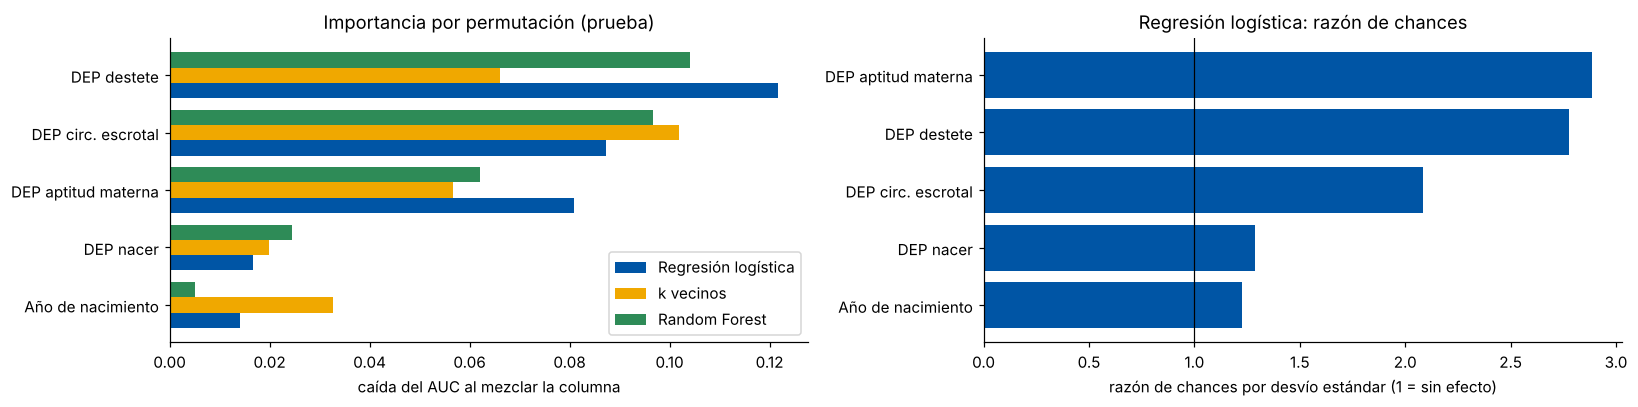

,Regresión logística,k vecinos,Random Forest
DEP nacer,0.017,0.020,0.024
DEP destete,0.122,0.066,0.104
DEP aptitud materna,0.081,0.057,0.062
DEP circ. escrotal,0.087,0.102,0.097
Año de nacimiento,0.014,0.033,0.005


In [18]:
imp = {}
for n in FINALES:
    r = permutation_importance(resultados[n]["modelo"], X_pru, y_pru, scoring="roc_auc", n_repeats=20, random_state=SEMILLA)
    imp[n] = pd.Series(r.importances_mean, index=[NOMBRES[c] for c in PREDICTORAS])
imp = pd.DataFrame(imp)
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 3.8))
imp.sort_values(MEJOR).plot.barh(ax=a, color=[COLOR_MODELO[n] for n in FINALES], width=0.8)
a.set_xlabel("caída del AUC al mezclar la columna"); a.set_title("Importancia por permutación (prueba)")
o = odds["razón de chances e^b"].sort_values()
b.barh(o.index, o.values, color=[AZUL if v >= 1 else ROJO for v in o.values]); b.axvline(1, color="black", lw=0.8)
b.set_xlabel("razón de chances por desvío estándar (1 = sin efecto)"); b.set_title("Regresión logística: razón de chances")
plt.tight_layout(); fig.savefig(FIG / f"tp3_importancia_{RAZA}.png", bbox_inches="tight"); plt.show()
imp.round(3)

**Qué se ve.** Los tres modelos usan las mismas tres variables: **destete, circunferencia escrotal y aptitud materna**. El peso al nacer y el año casi no aportan. Coincide con la regresión del TP2.

## D · Actividad complementaria

### D.1 · Clustering: tres algoritmos, uno de cada familia
Sobre las mismas cinco variables de la clasificación (imputadas y escaladas), **sin usar la etiqueta**, con los 1106 toros Braford. Se usan los tres algoritmos que nombra la consigna, porque cada uno entiende «grupo» de otra manera:
- **K-Means (centroides):** cada grupo es una nube alrededor de un centro. Pide k.
- **Aglomerativo con enlace de Ward (jerárquico):** cada toro empieza solo y se fusionan los grupos más parecidos; el dendrograma muestra todas las particiones posibles. Pide dónde cortar.
- **DBSCAN (densidad):** un grupo es una región densa separada por vacío; lo que queda aislado es ruido. No pide k, pide un radio (eps).

Si los tres llegan a la misma conclusión, la conclusión no depende del algoritmo. Primero, el número de grupos para K-Means, con el codo de la inercia, la silueta (mayor es mejor) y Davies-Bouldin (menor es mejor).

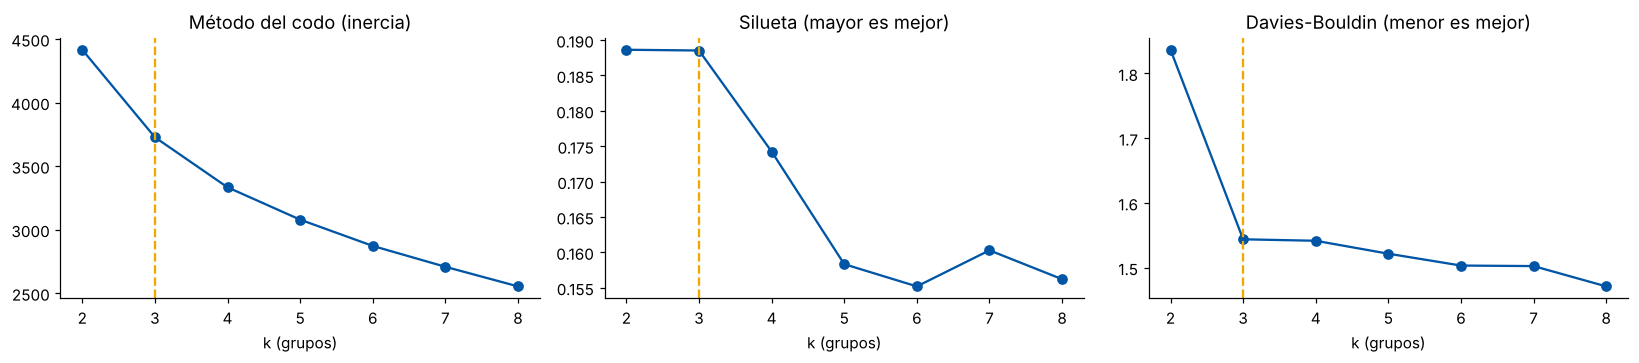

Empatan en silueta: [2, 3] · k elegido: 3 (silueta 0.189, Davies-Bouldin 1.54)
Davies-Bouldin por k: {2: 1.84, 3: 1.54, 4: 1.54, 5: 1.52, 6: 1.5, 7: 1.5, 8: 1.47}
Silueta por k: {2: 0.189, 3: 0.189, 4: 0.174, 5: 0.158, 6: 0.155, 7: 0.16, 8: 0.156}


In [19]:
prep = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
Z = prep.fit_transform(X)                          # todos los toros de la raza: el clustering no usa la etiqueta
ks = range(2, 9); inercia, silueta, db = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(Z)
    inercia.append(km.inertia_); silueta.append(silhouette_score(Z, km.labels_)); db.append(davies_bouldin_score(Z, km.labels_))
# Criterio: la silueta más alta; si hay empate (diferencia menor a 0,005), decide Davies-Bouldin (menor es mejor)
candidatos = [k for k, v in zip(ks, silueta) if v >= max(silueta) - 0.005]
K = min(candidatos, key=lambda k: db[k - 2])
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, v, t in zip(ejes, [inercia, silueta, db], ["Método del codo (inercia)", "Silueta (mayor es mejor)", "Davies-Bouldin (menor es mejor)"]):
    ax.plot(list(ks), v, marker="o", color=AZUL); ax.axvline(K, color=AMBAR, ls="--"); ax.set_title(t); ax.set_xlabel("k (grupos)")
plt.tight_layout(); fig.savefig(FIG / f"tp3_k_cluster_{RAZA}.png", bbox_inches="tight"); plt.show()
print(f"Empatan en silueta: {candidatos} · k elegido: {K} (silueta {silueta[K - 2]:.3f}, Davies-Bouldin {db[K - 2]:.2f})")
print("Davies-Bouldin por k:", {k: round(float(v), 2) for k, v in zip(ks, db)})
print("Silueta por k:", {k: round(float(v), 3) for k, v in zip(ks, silueta)})
km = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit(Z)
datos["grupo"] = km.labels_

**Qué se ve.** No hay un codo claro y la silueta es baja (0,19): **los toros no forman grupos bien separados**, se distribuyen en una nube continua. La silueta empata entre 2 y 3 grupos, y Davies-Bouldin desempata con claridad a favor de **k = 3** (1,54 contra 1,84). Se eligen 3 grupos, y se usa el mismo k en el aglomerativo para poder compararlos.

### D.1.b · Aglomerativo (Ward) y el dendrograma
Antes de usarlo hay que elegir el enlace, que define qué tan «cerca» están dos grupos. Se prueban los cuatro con k = 3, mirando la silueta **y los tamaños**.

Aglomerativo con k = 3 y cuatro enlaces:
                  tamaños silueta Davies-Bouldin
ward      [638, 308, 160]   0.151           1.65
complete  [810, 174, 122]   0.113           1.88
average      [1104, 1, 1]   0.465           0.35
single       [1104, 1, 1]   0.448           0.35


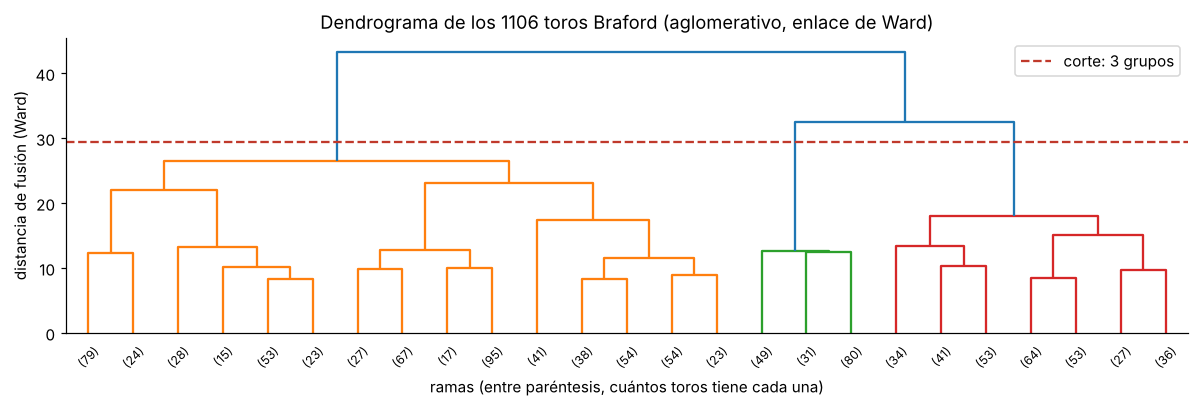

Últimas cinco fusiones a distancias [22.1, 23.2, 26.5, 32.5, 43.3] · el salto más grande deja 2 grupos
Ward con k = 3: tamaños [638, 308, 160] · silueta 0.151 · Rand ajustado contra K-Means 0.37


In [20]:
from scipy.cluster.hierarchy import linkage, dendrogram
# 1) Qué enlace usar: los cuatro con k = K, mirando silueta y tamaños
enlaces = {}
for enlace in ["ward", "complete", "average", "single"]:
    et = AgglomerativeClustering(n_clusters=K, linkage=enlace).fit_predict(Z)
    enlaces[enlace] = {"tamaños": sorted(np.bincount(et).tolist(), reverse=True), "silueta": silhouette_score(Z, et), "Davies-Bouldin": davies_bouldin_score(Z, et)}
print("Aglomerativo con k =", K, "y cuatro enlaces:")
print(pd.DataFrame(enlaces).T.to_string(formatters={"silueta": "{:.3f}".format, "Davies-Bouldin": "{:.2f}".format}))
# 2) Ward: el dendrograma de todos los toros (las últimas 25 fusiones) y el salto más grande
arbol = linkage(Z, method="ward")
saltos = np.diff(arbol[:, 2]); k_salto = len(arbol) + 1 - (int(np.argmax(saltos)) + 1)
fig, ax = plt.subplots(figsize=(11, 3.8))
dendrogram(arbol, truncate_mode="lastp", p=25, color_threshold=arbol[-(K - 1), 2], ax=ax, leaf_font_size=8)
ax.axhline((arbol[-K, 2] + arbol[-(K - 1), 2]) / 2, color=ROJO, ls="--", label=f"corte: {K} grupos")
ax.set_ylabel("distancia de fusión (Ward)"); ax.set_xlabel("ramas (entre paréntesis, cuántos toros tiene cada una)"); ax.legend()
ax.set_title(f"Dendrograma de los {len(Z)} toros {RAZA} (aglomerativo, enlace de Ward)")
plt.tight_layout(); fig.savefig(FIG / f"tp3_dendrograma_{RAZA}.png", bbox_inches="tight"); plt.show()
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)
datos["grupo_ward"] = ward
print(f"Últimas cinco fusiones a distancias {arbol[-5:, 2].round(1).tolist()} · el salto más grande deja {k_salto} grupos")
print(f"Ward con k = {K}: tamaños {np.bincount(ward).tolist()} · silueta {silhouette_score(Z, ward):.3f} · "
      f"Rand ajustado contra K-Means {adjusted_rand_score(km.labels_, ward):.2f}")

**Qué se ve.**
- **La trampa de la silueta:** los enlaces promedio y simple tienen la silueta más alta (0,46 y 0,45), pero dejan 1104 toros juntos y dos grupos de un toro cada uno: separaron a los dos toros más raros. Un índice alto no alcanza; hay que mirar los tamaños. Por eso se usa **Ward**, el único enlace que reparte y el comparable con K-Means (los dos minimizan la variación dentro de los grupos).
- **El dendrograma** tiene su salto más grande en la última fusión (deja 2 grupos), y el corte en 3 es el siguiente: coincide con la silueta en que 2 y 3 son las opciones razonables.
- **Ward con k = 3** da grupos de 638, 308 y 160 toros, con peor silueta que K-Means (0,15 contra 0,19). Coincide con K-Means solo en parte (Rand ajustado 0,37): con estructura débil, cada algoritmo corta el continuo en un lugar distinto. Pero, nombrados con el mismo criterio que K-Means (año más viejo, más destete, el otro), los perfiles son los mismos (sección D.1.d).

### D.1.c · DBSCAN: ¿hay regiones densas separadas?
El radio eps se elige con la distancia de cada toro a su quinto vecino, ordenada: el codo de esa curva es un eps razonable. Se prueba además un rango de eps para ver si en algún valor aparecen grupos.

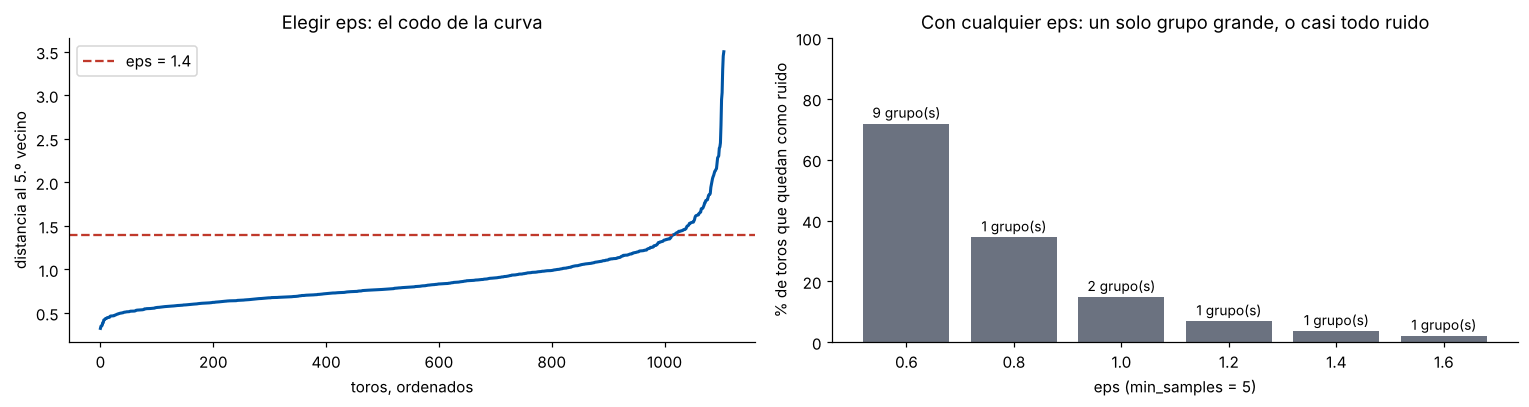

 eps  grupos  ruido  % ruido tamaños (los mayores)
 0.6       9    794     71.8       [261, 15, 7, 5]
 0.8       1    381     34.4                 [725]
 1.0       2    164     14.8              [938, 4]
 1.2       1     76      6.9                [1030]
 1.4       1     40      3.6                [1066]
 1.6       1     23      2.1                [1083]

DBSCAN (eps 1.4, min_samples 5): 1 grupo con 1066 toros · 40 toros de ruido (3.6%)
Top 10 % entre el ruido: 32% (en toda la raza: 38%)
Mediana de las variables, grupo contra ruido:
                       grupo    ruido
DEP nacer               0.34     0.60
DEP destete             6.97     2.62
DEP aptitud materna     0.62     4.34
DEP circ. escrotal      0.66     0.68
Año de nacimiento    2015.00  2013.00


In [21]:
# eps: la distancia de cada toro a su 5.º vecino, ordenada; el codo de la curva sugiere el radio
dist5 = np.sort(NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)[0][:, -1])
filas = []
for eps in [0.6, 0.8, 1.0, 1.2, 1.4, 1.6]:
    et = DBSCAN(eps=eps, min_samples=5).fit_predict(Z); tam = sorted(np.bincount(et[et >= 0]).tolist(), reverse=True) if (et >= 0).any() else []
    filas.append({"eps": eps, "grupos": int(et.max() + 1), "ruido": int((et == -1).sum()), "% ruido": 100 * (et == -1).mean(), "tamaños (los mayores)": tam[:4]})
tabla_eps = pd.DataFrame(filas)
EPS = 1.4
dbs = DBSCAN(eps=EPS, min_samples=5).fit_predict(Z); ruido = dbs == -1
datos["grupo_dbscan"] = dbs
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 3.8))
a.plot(dist5, color=AZUL, lw=2); a.axhline(EPS, color=ROJO, ls="--", label=f"eps = {EPS}")
a.set_xlabel("toros, ordenados"); a.set_ylabel("distancia al 5.º vecino"); a.legend(); a.set_title("Elegir eps: el codo de la curva")
b.bar(tabla_eps["eps"].astype(str), tabla_eps["% ruido"], color=GRIS)
for i, r in tabla_eps.iterrows(): b.text(i, r["% ruido"] + 2, f"{r['grupos']} grupo(s)", ha="center", fontsize=9)
b.set_xlabel("eps (min_samples = 5)"); b.set_ylabel("% de toros que quedan como ruido"); b.set_ylim(0, 100)
b.set_title("Con cualquier eps: un solo grupo grande, o casi todo ruido")
plt.tight_layout(); fig.savefig(FIG / f"tp3_dbscan_{RAZA}.png", bbox_inches="tight"); plt.show()
print(tabla_eps.round(1).to_string(index=False))
print(f"\nDBSCAN (eps {EPS}, min_samples 5): {int(dbs.max() + 1)} grupo con {(~ruido).sum()} toros · {ruido.sum()} toros de ruido ({ruido.mean():.1%})")
print(f"Top 10 % entre el ruido: {datos.loc[ruido, 'top10'].mean():.0%} (en toda la raza: {datos['top10'].mean():.0%})")
print("Mediana de las variables, grupo contra ruido:")
print(pd.DataFrame({"grupo": datos.loc[~ruido, PREDICTORAS].median(), "ruido": datos.loc[ruido, PREDICTORAS].median()}).rename(index=NOMBRES).round(2).to_string())

**Qué se ve.** Con cualquier eps razonable sale **un solo grupo grande y ruido**; con eps chico (0,6) se fragmenta y el 72 % queda como ruido. **No hay islas:** los tres grupos de K-Means y Ward son cortes de un continuo, no regiones separadas por vacío. No es un fallo de DBSCAN, es información: confirma lo que decía la silueta baja.

Lo útil de DBSCAN acá es el **ruido**: con eps 1,4 quedan 40 toros (3,6 %) sin vecinos cerca. Son toros con combinaciones extremas, sobre todo aptitud materna muy alta con destete bajo. El 32 % de ellos es top, parecido al resto: son raros, no errores, y por eso no se sacaron de los modelos.

### D.1.d · Los tres comparados, y contra la clase real
Los índices internos (silueta, Davies-Bouldin, Calinski-Harabasz) miden la forma de los grupos sin etiquetas; el externo (Rand ajustado) los compara con la clase top 10 %. Después, los cuatro gráficos en el plano de las dos primeras componentes principales (PCA): coloreados por cada algoritmo y por la clase real.

                     grupos  toros de ruido silueta Davies-Bouldin Calinski-Harabasz Rand aj. contra la clase Rand aj. contra K-Means ms
K-Means                 3.0             0.0   0.189           1.54               267                    0.033                   1.000 31
Aglomerativo (Ward)     3.0             0.0   0.151           1.65               199                    0.000                   0.372 17
DBSCAN                  1.0            40.0     NaN            NaN               NaN                      NaN                     NaN 19


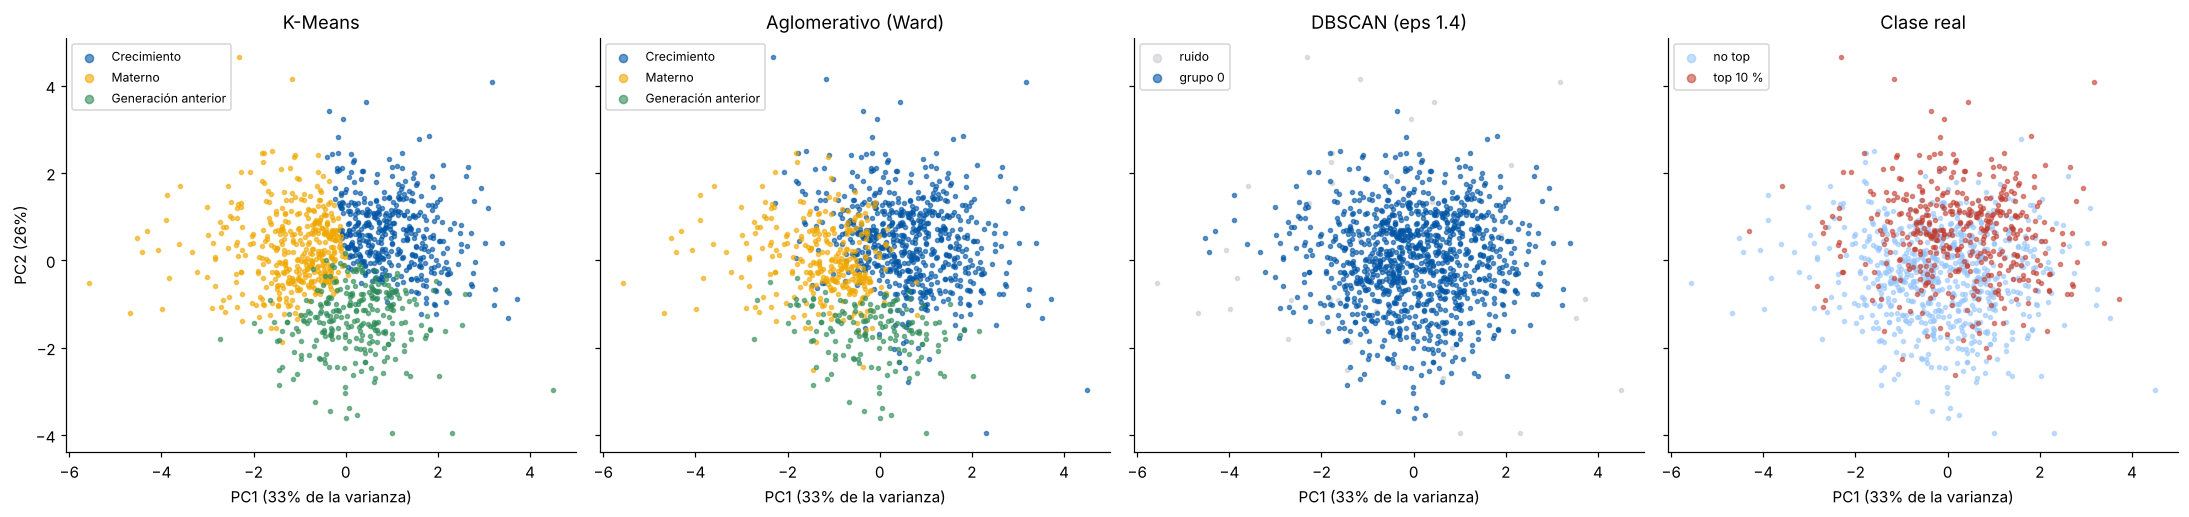


% de toros top 10 % en cada grupo:
  K-Means: Crecimiento 53% (420) · Materno 35% (412) · Generación anterior 18% (274)
  Ward: Crecimiento 49% (638) · Materno 28% (308) · Generación anterior 13% (160)
  DBSCAN: ruido 32% (40) · grupo 0 38% (1066)
Cargas de las componentes principales:
                      PC1   PC2
DEP nacer            0.36  0.19
DEP destete          0.69  0.00
DEP aptitud materna -0.58  0.33
DEP circ. escrotal   0.22  0.67
Año de nacimiento   -0.05  0.64


,toros,proporcion_top,DEP nacer,DEP destete,DEP aptitud materna,DEP circ. escrotal,Año de nacimiento,DEP_18_meses
Crecimiento,420,0.53,0.68,10.85,-0.49,0.93,2016.62,22.38
Materno,412,0.35,0.01,2.44,3.02,0.62,2016.01,17.70
Generación anterior,274,0.18,0.44,7.24,-0.49,0.34,2007.95,11.40


In [22]:
import time as _t
def evaluar(et, segundos):
    m = et >= 0; k_ = len(set(et[m]))
    return {"grupos": k_, "toros de ruido": int((~m).sum()),
            "silueta": silhouette_score(Z[m], et[m]) if k_ > 1 else np.nan,
            "Davies-Bouldin": davies_bouldin_score(Z[m], et[m]) if k_ > 1 else np.nan,
            "Calinski-Harabasz": calinski_harabasz_score(Z[m], et[m]) if k_ > 1 else np.nan,
            "Rand aj. contra la clase": adjusted_rand_score(datos["top10"][m], et[m]) if k_ > 1 else np.nan,
            "Rand aj. contra K-Means": adjusted_rand_score(km.labels_[m], et[m]) if k_ > 1 else np.nan, "ms": segundos * 1000}
ALG_CLUSTER = {"K-Means": lambda: KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit_predict(Z),
               "Aglomerativo (Ward)": lambda: AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z),
               "DBSCAN": lambda: DBSCAN(eps=EPS, min_samples=5).fit_predict(Z)}
comp_cluster = {}
for n, f in ALG_CLUSTER.items():
    t0 = _t.perf_counter(); et = f(); comp_cluster[n] = evaluar(et, _t.perf_counter() - t0)
comp_cluster = pd.DataFrame(comp_cluster).T
print(comp_cluster.to_string(formatters={c: "{:.3f}".format for c in ["silueta", "Rand aj. contra la clase", "Rand aj. contra K-Means"]} |
                                         {"Davies-Bouldin": "{:.2f}".format, "Calinski-Harabasz": "{:.0f}".format, "ms": "{:.0f}".format}))
# Nombre de cada grupo de K-Means según su centroide (el año más viejo; el de más destete; el otro)
def nombrar(col):
    medias = datos.groupby(col)[PREDICTORAS].mean()
    g_viejo = int(medias["Anio_Nacimiento"].idxmin()); resto = [g for g in medias.index if g != g_viejo]
    g_crec = max(resto, key=lambda g: medias.loc[g, "PesoDestete_DEP"])
    return {g_viejo: "Generación anterior", g_crec: "Crecimiento", **{g: "Materno" for g in resto if g != g_crec}}
NOMBRE_GRUPO, NOMBRE_WARD = nombrar("grupo"), nombrar("grupo_ward")     # el mismo criterio para los dos
pca = PCA(n_components=2, random_state=SEMILLA).fit(Z); P = pca.transform(Z)
fig, ejes = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True, sharey=True)
COLOR_PERFIL = {"Crecimiento": AZUL, "Materno": AMBAR, "Generación anterior": VERDE}
paneles = [("K-Means", datos["grupo"], NOMBRE_GRUPO), ("Aglomerativo (Ward)", datos["grupo_ward"], NOMBRE_WARD), (f"DBSCAN (eps {EPS})", datos["grupo_dbscan"], {})]
for ax, (t, et, nom) in zip(ejes, paneles):
    for g in sorted(set(et)):
        m = (et == g).values
        ax.scatter(P[m, 0], P[m, 1], s=7, alpha=0.6, color="#c9ccd1" if g == -1 else COLOR_PERFIL.get(nom.get(g), AZUL),
                   label="ruido" if g == -1 else nom.get(g, f"grupo {g}"))
    ax.set_title(t)
for c, col in [(0, "#93c5fd"), (1, ROJO)]:
    m = (datos["top10"] == c).values; ejes[3].scatter(P[m, 0], P[m, 1], s=7, alpha=0.55, color=col, label=CLASES[c])
ejes[3].set_title("Clase real")
for ax in ejes: ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)"); ax.legend(fontsize=8, markerscale=2)
ejes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); fig.savefig(FIG / f"tp3_cluster_pca_{RAZA}.png", bbox_inches="tight"); plt.show()
print("\n% de toros top 10 % en cada grupo:")
for n, col in [("K-Means", "grupo"), ("Ward", "grupo_ward"), ("DBSCAN", "grupo_dbscan")]:
    nom = {"K-Means": NOMBRE_GRUPO, "Ward": NOMBRE_WARD}.get(n, {})
    print(f"  {n}: " + " · ".join(f"{'ruido' if g == -1 else nom.get(g, f'grupo {g}')} {v:.0%} ({(datos[col] == g).sum()})"
                                  for g, v in datos.groupby(col)["top10"].mean().items()))
perfil = datos.groupby("grupo").agg(toros=("top10", "size"), proporcion_top=("top10", "mean"), **{NOMBRES[c]: (c, "mean") for c in PREDICTORAS},
                                    DEP_18_meses=("Peso18Meses_DEP", "mean"))
perfil.index = [NOMBRE_GRUPO[g] for g in perfil.index]
print("Cargas de las componentes principales:")
print(pd.DataFrame(pca.components_.T, index=[NOMBRES[c] for c in PREDICTORAS], columns=["PC1", "PC2"]).round(2).to_string())
perfil.round(2)

**Qué se ve.**
- **K-Means es el mejor de los tres:** la mejor silueta (0,19 contra 0,15), el mejor Davies-Bouldin (1,54 contra 1,65) y el mejor Calinski-Harabasz, en milisegundos. DBSCAN no forma grupos, así que sus índices no se pueden calcular.
- **¿Los clusters coinciden con las clases?** No, con ninguno de los tres: Rand ajustado de 0,03 (K-Means) y 0,00 (Ward), prácticamente azar; DBSCAN deja a casi todos en un solo grupo. La estructura natural de los datos no es «top contra no top».
- **¿Hay subestructuras?** Sí: tres perfiles de toro, que K-Means y Ward encuentran con bordes distintos:
  - **Crecimiento** (K-Means: 420 toros): mucho destete (10,9 kg), aptitud materna negativa, más circunferencia escrotal y más peso al nacer; toros nuevos (2017 en promedio). El 53 % es top (en Ward, el grupo equivalente tiene 49 %).
  - **Materno** (412 toros): poco destete (2,4 kg) y la aptitud materna más alta (3,0 kg); también nuevos. El 35 % es top (Ward: 28 %).
  - **Generación anterior** (274 toros): nacidos alrededor de 2008, con DEP más bajas en general. Solo el 18 % es top (Ward: 13 %): es la tendencia genética de la raza.
- La primera componente principal es el eje destete contra aptitud materna, y la segunda, la circunferencia escrotal y el año.
- **Qué aporta que el clasificador no da:** hay toros top en los tres perfiles: se llega al top 10 % tanto por el camino del crecimiento como por el materno. Eso explica por qué ninguna variable sola separa las clases y por qué el clasificador necesita combinarlas. Y DBSCAN agrega una lista de toros raros para mirar uno por uno.

### D.2 · El ensamble contra los clasificadores individuales
Random Forest es un ensamble por bagging. Se compara con la logística y k vecinos con las mismas métricas, y se suma el costo: tiempo de ajuste, tiempo de predicción e interpretabilidad.

In [23]:
comp = pd.DataFrame({n: {**{m: resultados[n]["prueba"][m] for m in ["AUC", "F1", "Kappa"]},
                         "AUC CV": resultados[n]["AUC CV"][0], "AUC CV desvío": resultados[n]["AUC CV"][1],
                         "AUC entrenamiento": resultados[n]["entrenamiento"]["AUC"]} for n in FINALES}).T
t_pred = {}
for n in FINALES:
    t0 = time.perf_counter(); [resultados[n]["modelo"].predict_proba(X_pru) for _ in range(20)]; t_pred[n] = (time.perf_counter() - t0) / 20 * 1000
t_fit = {}
for n in FINALES:
    m = resultados[n]["modelo"]; t0 = time.perf_counter(); m.fit(X_ent, y_ent); t_fit[n] = (time.perf_counter() - t0) * 1000
comp["ajuste (ms)"] = pd.Series(t_fit); comp["predicción de 222 toros (ms)"] = pd.Series(t_pred)
comp["parámetros que se leen"] = ["6 (intercepto y 5 coeficientes)", f"ninguno: guarda {len(X_ent)} toros", "300 árboles"]
dif = resultados["Random Forest"]["AUC CV"][0] - max(resultados[n]["AUC CV"][0] for n in ["Regresión logística", "k vecinos"])
print(f"Random Forest (ensamble) menos el mejor individual, en AUC de validación cruzada: {dif:+.3f}")
comp

Random Forest (ensamble) menos el mejor individual, en AUC de validación cruzada: -0.016


,AUC,F1,Kappa,AUC CV,AUC CV desvío,AUC entrenamiento,ajuste (ms),predicción de 222 toros (ms),parámetros que se leen
Regresión logística,0.774500,0.596026,0.391808,0.819851,0.020761,0.826027,6.986462,1.767491,6 (intercepto y 5 coeficientes)
k vecinos,0.785628,0.538462,0.369676,0.812884,0.018218,0.826104,4.314251,7.467652,ninguno: guarda 884 toros
Random Forest,0.759058,0.595745,0.417564,0.803746,0.018871,0.907588,574.570173,69.299047,300 árboles


**Qué se ve.** **El ensamble no mejoró:** su AUC de validación cruzada es 0,016 menor que el de la logística, y en esta computadora tarda decenas de veces más en entrenar y en predecir (cientos de milisegundos contra unos pocos). Además pierde interpretabilidad: la logística se explica con 5 coeficientes; el bosque, con 300 árboles. La ganancia **no justifica** la complejidad en este problema, porque la relación es casi aditiva y no hay interacciones que el bosque pueda aprovechar.

## 7 · Réplica en Brangus
Los mismos tres clasificadores, la misma partición estratificada y las mismas grillas.

In [24]:
def correr_raza(raza):
    d = toros[toros["Raza"] == raza].reset_index(drop=True)
    Xe, Xp, ye, yp = train_test_split(d[PREDICTORAS], d["top10"], test_size=0.2, random_state=SEMILLA, stratify=d["top10"])
    modelos = {"Regresión logística": flujo(LogisticRegression(max_iter=1000)),
               "k vecinos": GridSearchCV(flujo(KNeighborsClassifier()), grilla_knn, cv=pliegues, scoring="roc_auc"),
               "Random Forest": GridSearchCV(flujo(RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1), escalar=False),
                                             grilla_rf, cv=pliegues, scoring="roc_auc", n_jobs=-1)}
    filas = {}
    for n, m in modelos.items():
        m.fit(Xe, ye); fin = m.best_estimator_ if hasattr(m, "best_estimator_") else m
        cv = cross_validate(fin, Xe, ye, cv=pliegues, scoring="roc_auc")
        me, mp = metricas(ye, fin.predict_proba(Xe)[:, 1]), metricas(yp, fin.predict_proba(Xp)[:, 1])
        filas[n] = {"AUC ent.": me["AUC"], "AUC prueba": mp["AUC"], "AUC CV": cv["test_score"].mean(), "AUC CV desvío": cv["test_score"].std(),
                    "Exactitud": mp["Exactitud"], "Precisión": mp["Precisión"], "Exhaustividad": mp["Exhaustividad"], "F1": mp["F1"], "Kappa": mp["Kappa"],
                    "hiperparámetros": getattr(m, "best_params_", "por defecto")}
    return pd.DataFrame(filas).T

tabla_bg = correr_raza("Brangus")
tabla_bg

,AUC ent.,AUC prueba,AUC CV,AUC CV desvío,Exactitud,Precisión,Exhaustividad,F1,Kappa,hiperparámetros
Regresión logística,0.899785,0.885753,0.896568,0.010595,0.836735,0.791209,0.774194,0.782609,0.651914,por defecto
k vecinos,0.891288,0.871145,0.884039,0.018208,0.8,0.789474,0.645161,0.710059,0.559757,"{'modelo__n_neighbors': 75, 'modelo__weights':..."
Random Forest,0.962728,0.873019,0.883314,0.016584,0.808163,0.780488,0.688172,0.731429,0.583137,"{'modelo__max_depth': 6, 'modelo__max_features..."


**Qué se ve.** En Brangus se repite el orden (la logística primera, con AUC 0,886 en prueba y 0,897 ± 0,011 en validación cruzada) con un nivel mucho más alto, y Random Forest vuelve a mostrar la mayor brecha entre entrenamiento y prueba. Como en el TP2 y en el TP1, la raza cambia cuánto se puede anticipar.

In [25]:
salida = {"raza": RAZA, "n": len(datos), "n_ent": len(X_ent), "n_pru": len(X_pru), "prop_top": float(y.mean()), "top_pru": int(y_pru.sum()),
          "mejor": MEJOR, "conteo": json.loads(conteo.to_json(orient="index")),
          "modelos": {n: {"entrenamiento": resultados[n]["entrenamiento"], "prueba": resultados[n]["prueba"], "AUC CV": resultados[n]["AUC CV"],
                          "F1 CV": resultados[n]["F1 CV"]} for n in resultados},
          "matrices": {n: confusion_matrix(y_pru, (resultados[n]["prob"] >= 0.5).astype(int)).tolist() for n in ["Referencia: la clase más frecuente"] + FINALES},
          "hiper_knn": busq_knn.best_params_, "hiper_rf": busq_rf.best_params_, "odds": odds["razón de chances e^b"].to_dict(),
          "umbral_f1": float(u_f1), "umbral_tabla": {f"{u:.2f}": metricas(y_pru, prob, u) for u in [0.3, 0.5, u_f1]},
          "importancia": imp.to_dict(), "k_cluster": int(K), "silueta": dict(zip(map(str, ks), map(float, silueta))),
          "davies_bouldin": dict(zip(map(str, ks), map(float, db))), "ari": float(adjusted_rand_score(datos["top10"], datos["grupo"])),
          "perfil_grupos": json.loads(perfil.to_json(orient="index")), "pca_var": pca.explained_variance_ratio_.tolist(),
          "clustering": json.loads(comp_cluster.to_json(orient="index")), "enlaces": {k: {"tamaños": v["tamaños"], "silueta": float(v["silueta"])} for k, v in enlaces.items()},
          "ward_k_salto": int(k_salto), "eps": EPS, "tabla_eps": json.loads(tabla_eps.to_json(orient="records")),
          "dbscan_ruido": int(ruido.sum()), "dbscan_top_ruido": float(datos.loc[ruido, "top10"].mean()),
          "top_por_grupo": {"K-Means": {NOMBRE_GRUPO[g]: float(v) for g, v in datos.groupby("grupo")["top10"].mean().items()},
                            "Ward": {NOMBRE_WARD[g]: [float(v), int((datos["grupo_ward"] == g).sum())] for g, v in datos.groupby("grupo_ward")["top10"].mean().items()}},
          "ensamble_dif_auc_cv": float(dif), "tiempos_ajuste_ms": t_fit, "tiempos_pred_ms": t_pred,
          "brangus": json.loads(tabla_bg.drop(columns="hiperparámetros").to_json(orient="index")),
          "brangus_hiper": {k: str(v) for k, v in tabla_bg["hiperparámetros"].items()}}
Path("resultados_tp3.json").write_text(json.dumps(salida, ensure_ascii=False, indent=1, default=float))
print("Guardado: resultados_tp3.json y las figuras en figuras/")

Guardado: resultados_tp3.json y las figuras en figuras/


## 8 · Cuestionario de interpretación

**1. ¿Cuál fue el clasificador más adecuado? ¿Cambiaría si se priorizara la exhaustividad o la precisión?**
La **regresión logística**: mayor AUC en validación cruzada (0,820 ± 0,021), mejor F1 (0,596) y mayor exhaustividad (0,536) en prueba, y la menor brecha entre entrenamiento y prueba. Las matrices de confusión muestran que el error dominante de los tres es el falso negativo. Si se priorizara la **precisión**, ganaría k vecinos (0,761: de cada 4 toros que marca, 3 son top), a costa de encontrar solo el 42 % de los top. Si se priorizara la **exhaustividad**, gana la logística, y bajando el umbral a 0,30 encuentra el 76 % de los top con precisión 0,58. Para elegir pajuelas, donde dejar pasar un buen toro cuesta más que revisar uno de más, conviene priorizar exhaustividad.

**2. ¿Hubo sobreajuste o subajuste? ¿Qué impacto tuvo el desbalance?**
- **Random Forest con valores por defecto sobreajusta por completo** (AUC 1,000 en entrenamiento contra 0,731 en prueba). Con profundidad 6 y 10 toros por hoja mejora, pero conserva una brecha de 0,15: es varianza.
- **k vecinos con k = 5 sobreajusta** (0,903 contra 0,728); con k = 101 la brecha se cierra.
- **La logística no sobreajusta** (0,826 contra 0,774): su límite es el sesgo, y la curva de aprendizaje muestra que más toros no lo cambiarían.
- **Desbalance:** con 62/38 la referencia trivial acierta el 62 % sin encontrar ningún top (Kappa 0): la exactitud sola engaña. Se abordó estratificando la partición y la validación cruzada, evaluando con F1, Kappa y AUC, pesando las clases (la exhaustividad de la logística sube de 0,54 a 0,63 sin cambiar el AUC) y moviendo el umbral.

**3. ¿Qué factores del problema explican el desempeño? ¿El clustering y el ensamble aportan?**
- **Clases poco separables y relación casi lineal.** Las distribuciones de las dos clases se superponen en todas las variables, y la señal es una combinación aditiva de destete, aptitud materna y circunferencia escrotal. Con 5 variables y 884 toros, la frontera que mejor generaliza es casi una recta: por eso gana la logística y k vecinos necesita k = 101 para acercarse.
- **Clustering:** con tres algoritmos de familias distintas, la respuesta es la misma. **No hay grupos separados** (DBSCAN encuentra un solo grupo y 40 toros raros; la silueta de K-Means es 0,19) y los grupos **no coinciden** con la clase (Rand ajustado 0,03 con K-Means y 0,00 con Ward). Pero K-Means, el mejor de los tres en todos los índices, y Ward encuentran los mismos tres perfiles (crecimiento, materno y generación anterior), y eso explica el problema: se llega al top 10 % tanto por el perfil de crecimiento como por el materno, así que ninguna variable sola alcanza; y los toros más viejos casi no llegan, por la tendencia genética.
- **Ensamble:** Random Forest no mejoró (AUC de validación cruzada 0,016 menor), costó decenas de veces más tiempo de entrenamiento y perdió interpretabilidad. **No se justifica** aquí. Sería distinto con relaciones no lineales o interacciones fuertes, que estos datos no tienen.
- **Raza:** en Brangus todo es más predecible (AUC 0,89), igual que en el TP1 y el TP2.

## 9 · Conclusión
Para anticipar si un toro Braford estará en el 10 % superior a los 18 meses alcanza una **regresión logística** sobre sus DEP tempranas: AUC cercano a 0,80, sin sobreajuste e interpretable (aptitud materna, destete y circunferencia escrotal multiplican por 2 a 3 las chances por cada desvío estándar). Ni k vecinos ni el ensamble la superan. Con un umbral de 0,30 sirve como primer filtro: encuentra a 3 de cada 4 toros top. Es la misma conclusión que la regresión del TP2: **en este problema, el modelo simple es el mejor**.